# Localized Multimodal Vision-Semantic Oracle
### Interactive Verification & Live Device Inspection
**Student:** M.L. Booso (IT23452916)
Zero-cloud visual defect verification for mobile applications using **4-bit quantized Qwen2-VL**, **Universal SAHI Dynamic Slicing**, and **Dual-Modality AST Layout Collision Pruning** with live ADB device connectivity.

In [20]:
# Cell 1: Hardware & Environment Verification & GPU VRAM Cleanup
import sys
import os
import gc
from pathlib import Path
import torch

# Ensure clean VRAM state
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Add package to Python path
NOTEBOOK_DIR = Path.cwd() if Path.cwd().name == 'notebooks' else (Path.cwd() / 'vision_oracle' / 'notebooks').resolve()
VISION_ORACLE_DIR = NOTEBOOK_DIR.parent.resolve()
REPO_ROOT = VISION_ORACLE_DIR.parent.resolve()

for p in [str(VISION_ORACLE_DIR), str(REPO_ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)

print(f'[*] Python Executable : {sys.executable}')
print(f'[*] PyTorch Version   : {torch.__version__}')
print(f'[*] CUDA Available    : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'[*] Active GPU        : {torch.cuda.get_device_name(0)}')
    print(f'[*] Total VRAM        : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
    print(f'[*] Free VRAM         : {(torch.cuda.get_device_properties(0).total_memory - torch.cuda.memory_allocated(0)) / (1024**3):.2f} GB')


[*] Python Executable : c:\Users\hp\AppData\Local\Programs\Python\Python313\python.exe
[*] PyTorch Version   : 2.6.0+cu124
[*] CUDA Available    : True
[*] Active GPU        : NVIDIA GeForce RTX 3050 Laptop GPU
[*] Total VRAM        : 4.00 GB
[*] Free VRAM         : 2.66 GB


In [21]:
# Cell 2: Import Local Vision Oracle Engine Modules
import importlib
import local_vision_oracle.engine
importlib.reload(local_vision_oracle.engine)
from local_vision_oracle.engine import OracleEngine, TransformersInferenceBackend
from local_vision_oracle.preprocessor import ImagePreprocessor
from local_vision_oracle.pruner import HierarchyPruner, PrunedNode
from local_vision_oracle.schemas import DefectType, C3OracleResult
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

print('[+] Local Vision Oracle modules imported and reloaded successfully.')


[+] Local Vision Oracle modules imported and reloaded successfully.


In [22]:
# Cell 3: Initialize 4-bit Quantized Model & LoRA Adapter
import gc
import torch

# Garbage collect and free VRAM before loading
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

def resolve_path(rel_candidate: str) -> str:
    search_roots = [
        Path.cwd() / "vision_oracle",
        Path.cwd(),
        NOTEBOOK_DIR,
        VISION_ORACLE_DIR,
        REPO_ROOT,
        REPO_ROOT.parent,
        Path(r'D:/university/Resesarch'),
    ]
    for root in search_roots:
        target = (root / rel_candidate).resolve()
        if target.exists():
            return str(target)
    return str((Path(r'D:/university/Resesarch') / rel_candidate).resolve())

BASE_MODEL_PATH = resolve_path('RD/models/Qwen2-VL-2B-Instruct')
LORA_WEIGHTS_PATH = resolve_path('models/c3_qwen2vl_2b_lora_step246') or resolve_path('results/c3_lora_final')

print(f'[*] Base Model Path   : {BASE_MODEL_PATH}')
print(f'[*] LoRA Weights Path : {LORA_WEIGHTS_PATH}')
assert Path(BASE_MODEL_PATH).exists(), f'Model directory missing: {BASE_MODEL_PATH}'
assert Path(LORA_WEIGHTS_PATH).exists(), f'LoRA weights missing: {LORA_WEIGHTS_PATH}'

# Initialize 4-bit NF4 quantized backend with CPU offload resilience
backend = TransformersInferenceBackend(
    model_name_or_path=BASE_MODEL_PATH,
    adapter_dir=LORA_WEIGHTS_PATH,
    quantization_bit=4,
    lazy_load=False,
)

# Wrap in full C3 Oracle Pipeline
oracle = OracleEngine(backend=backend)
print('[+] Oracle Engine initialized and warmed in GPU VRAM.')


[*] Base Model Path   : D:\university\Resesarch\RD\models\Qwen2-VL-2B-Instruct
[*] LoRA Weights Path : D:\university\Resesarch\results\c3_lora_final


Loading weights: 100%|██████████| 729/729 [00:09<00:00, 79.33it/s] 


[+] Oracle Engine initialized and warmed in GPU VRAM.


In [23]:
import json
# Cell 4: Visual Overlay Helper for Defect Inspection (Multi-Region Support)
def plot_oracle_result(image_path: str, result: C3OracleResult):
    img = Image.open(image_path).convert('RGB')
    w, h = img.size
    
    fig, ax = plt.subplots(1, figsize=(8, 12), dpi=100)
    ax.imshow(img)
    ax.axis('off')
    
    verdict = result.verdict
    all_regions = result.metadata.get('all_detected_regions', [])
    
    title_str = f'Screen: {result.screen_id} | Defect: {verdict.has_defect}'
    if verdict.has_defect:
        title_str += f' ({verdict.defect_type.value}) - Conf: {verdict.confidence:.2f}'
        if all_regions:
            title_str += f' [{len(all_regions)} Regions Detected]'
        color = 'red'
    else:
        title_str += ' (Clean UI) - Conf: 1.00'
        color = 'lime'
        
    plt.title(title_str, fontsize=12, fontweight='bold', pad=12)
    
    # Render all detected multi-slice defect bounding boxes
    boxes_to_draw = []
    if all_regions:
        for r in all_regions:
            if r.get('bounding_box'):
                boxes_to_draw.append((r['bounding_box'], r.get('defect_type', 'defect'), r.get('confidence', 1.0), r.get('slice_index', 0)))
    elif verdict.has_defect and verdict.bounding_box:
        boxes_to_draw.append((verdict.bounding_box, verdict.defect_type.value, verdict.confidence, 0))
        
    for bbox, label_type, conf, s_idx in boxes_to_draw:
        ymin, xmin, ymax, xmax = bbox
        px_xmin = (xmin / 1000.0) * w
        px_ymin = (ymin / 1000.0) * h
        px_xmax = (xmax / 1000.0) * w
        px_ymax = (ymax / 1000.0) * h
        box_w = max(4, px_xmax - px_xmin)
        box_h = max(4, px_ymax - px_ymin)
        
        rect = patches.Rectangle(
            (px_xmin, px_ymin), box_w, box_h,
            linewidth=3, edgecolor=color, facecolor='none', linestyle='--'
        )
        ax.add_patch(rect)
        
        label = f'[Slice {s_idx}] {str(label_type).upper()} [{conf:.2f}]'
        ax.text(
            px_xmin + 8, min(h - 10, px_ymin + 28),
            label,
            fontsize=10, fontweight='bold', color='white',
            bbox=dict(facecolor=color, alpha=0.8, edgecolor='none', boxstyle='round,pad=0.3')
        )
        
    plt.tight_layout()
    plt.show()
    print('\n=== STRUCTURED IF-C3-to-C4 VERDICT ===')
    print(json.dumps(result.to_dict(), indent=2))

print('[+] Visual overlay function defined (multi-region support enabled).')


[+] Visual overlay function defined (multi-region support enabled).


## 2. Universal SAHI Slicing: Real-World Mobile Defect Detection
The target screen below (`opening_screen.png`) is a 720x1600 tall mobile screen where a fixed bottom navigation bar occludes the 'Active Reservation Pass' card.
- **Global Downsampling Failure:** When squashed into 262,144 pixels, the 50px overlap becomes blurred (<1 visual patch), returning a false negative (`clean`).
- **Universal SAHI Recovery:** The engine partitions tall screens ($H \ge 1.25 W$) into native aspect ratio slices. The bottom slice ($y \in [0.75, 1.00]$) captures the bottom navigation occlusion at full resolution, triggering a true positive detection mapped back to global coordinates.

[*] Evaluating screen: d:\university\Resesarch\J26-SE-334\vision_oracle\notebooks\opening_screen.png


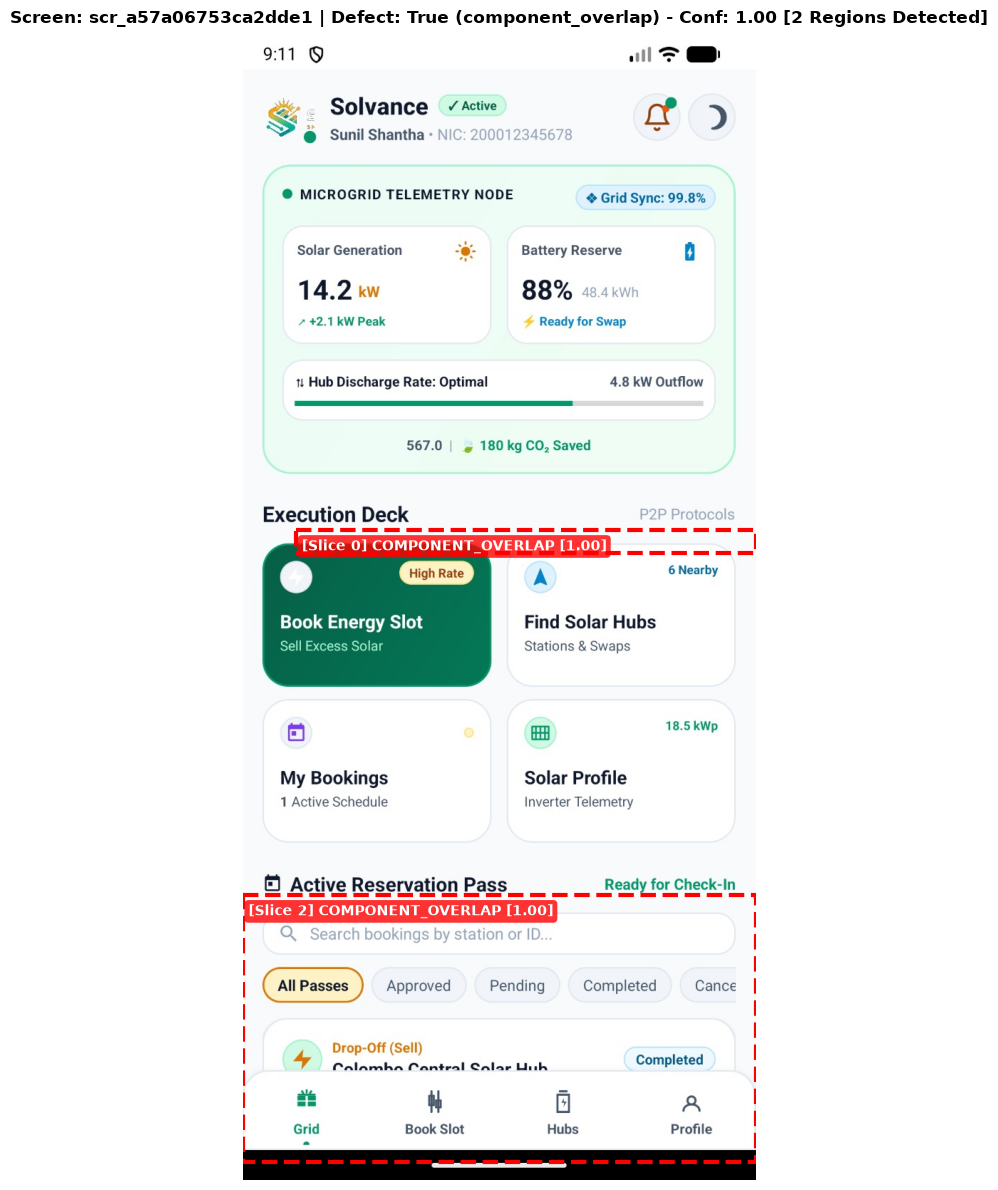


=== STRUCTURED IF-C3-to-C4 VERDICT ===
{
  "screen_id": "scr_a57a06753ca2dde1",
  "verdict": {
    "has_defect": true,
    "defect_type": "component_overlap",
    "sub_category": null,
    "confidence": 1.0,
    "bounding_box": [
      430,
      104,
      450,
      1000
    ],
    "affected_element_id": "com.solvance.android:id/execution_deck",
    "explanation": "[Slice 0] Component overlap defect: widget AppCompatTextView occludes AppCompatTextView (com.solvance.android:id/execution_deck). | [Slice 2] Visual UI rendering defect: abnormal component collision detected on screen."
  },
  "latency_breakdown": {
    "capture_ms": 0.0,
    "preprocess_ms": 51.62,
    "prune_ms": 0.0,
    "inference_ms": 68515.98,
    "total_pipeline_ms": 68567.6,
    "meets_sla": false
  },
  "timestamp": "2026-10-16T10:27:51.775659+00:00",
  "engine_used": "qwen2-vl-awq-4bit",
  "metadata": {
    "screen_id": "scr_a57a06753ca2dde1",
    "action_context": "User navigated to home screen; checking reserv

In [24]:
# Cell 5: Evaluate Screen with Universal SAHI Slicing (Initial opening_screen.png Test)
target_screen_candidate = NOTEBOOK_DIR / 'opening_screen.png'
if not target_screen_candidate.exists():
    target_screen_candidate = Path(resolve_path('opening_screen.png'))

target_screen = str(target_screen_candidate)
print(f'[*] Evaluating screen: {target_screen}')
assert Path(target_screen).exists(), f'Target screen file not found: {target_screen}'

# Evaluate with full multi-slice SAHI enabled
result = oracle.evaluate(
    image_input=target_screen,
    action_context='User navigated to home screen; checking reservation card visibility',
    enable_sahi=True,
)

# Render visual bounding box overlay and print C4 JSON verdict
plot_oracle_result(target_screen, result)


### 2B. Multi-Defect Evaluation: Glitched ShopEase App (Multiple Visual Collisions)
Evaluates `Glitched ShopEase Ecommerce App.png` through multi-slice SAHI dynamic tiling to detect both header text overlaps and component collisions across different viewport slices simultaneously.

[*] Evaluating glitched screen: d:\university\Resesarch\J26-SE-334\vision_oracle\notebooks\Glitched ShopEase Ecommerce App.png


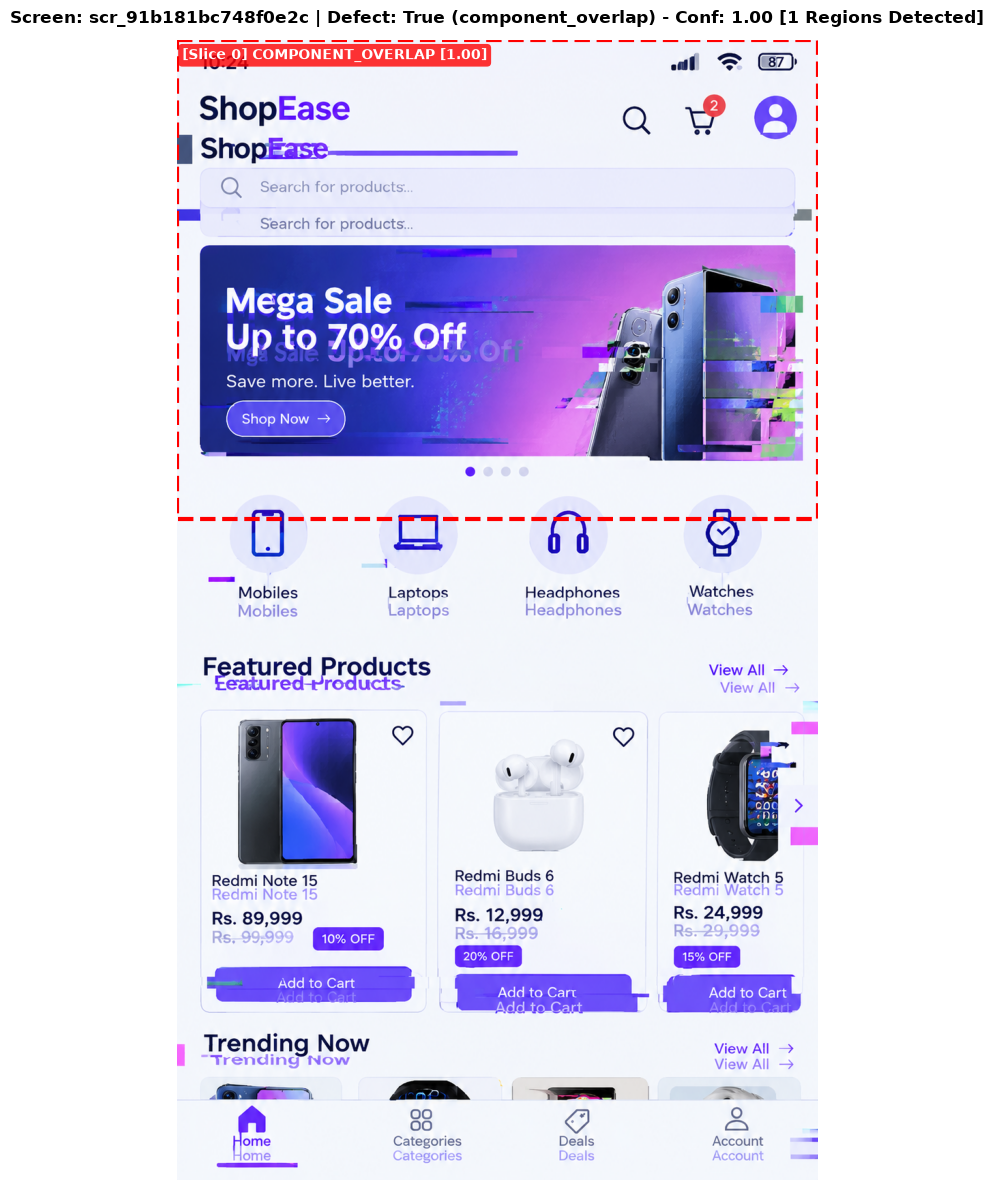


=== STRUCTURED IF-C3-to-C4 VERDICT ===
{
  "screen_id": "scr_91b181bc748f0e2c",
  "verdict": {
    "has_defect": true,
    "defect_type": "component_overlap",
    "sub_category": null,
    "confidence": 1.0,
    "bounding_box": [
      0,
      0,
      420,
      1000
    ],
    "affected_element_id": null,
    "explanation": "[Slice 0] Visual UI rendering defect: abnormal component collision detected on screen."
  },
  "latency_breakdown": {
    "capture_ms": 0.0,
    "preprocess_ms": 108.29,
    "prune_ms": 0.0,
    "inference_ms": 107206.19,
    "total_pipeline_ms": 107314.48,
    "meets_sla": false
  },
  "timestamp": "2026-10-16T10:45:30.076699+00:00",
  "engine_used": "qwen2-vl-awq-4bit",
  "metadata": {
    "screen_id": "scr_91b181bc748f0e2c",
    "action_context": "User browsing ecommerce catalog; detecting header and button collisions",
    "detected_by": "sahi_dynamic_tiling",
    "sahi_slices_with_defects": [
      0
    ],
    "all_detected_regions": [
      {
        "sl

In [26]:
# Cell 5B: Evaluate Glitched ShopEase Screen with Multi-Slice Dynamic Slicing
shopease_candidate = NOTEBOOK_DIR / 'Glitched ShopEase Ecommerce App.png'
if not shopease_candidate.exists():
    shopease_candidate = Path(resolve_path('Glitched ShopEase Ecommerce App.png'))

shopease_screen = str(shopease_candidate)
print(f'[*] Evaluating glitched screen: {shopease_screen}')
assert Path(shopease_screen).exists(), f'Target screen file not found: {shopease_screen}'

shopease_result = oracle.evaluate(
    image_input=shopease_screen,
    action_context='User browsing ecommerce catalog; detecting header and button collisions',
    enable_sahi=True,
)

# Render all detected defect regions across the screen
plot_oracle_result(shopease_screen, shopease_result)


## 3. Ultra-Fast AST Pruning & Layout Collision Verification (CLAIM-01)
When Android accessibility XML/JSON hierarchy is available, the oracle performs instantaneous (<5ms) geometric bounding box collision detection on the CPU, bypassing model inference entirely for obvious DOM-level widget overlaps.

In [27]:
# Cell 6: Demonstrate AST Layout Collision Detection (<5ms on CPU)
synthetic_hierarchy = [
    PrunedNode(
        element_id='card_reservation_pass',
        class_name='android.widget.CardView',
        text='Active Reservation: Express Train 102',
        content_desc='Reservation Card',
        bounds=[700, 50, 850, 950],
        clickable=True,
        scrollable=False,
    ),
    PrunedNode(
        element_id='bottom_navigation_bar',
        class_name='com.google.android.material.bottomnavigation.BottomNavigationView',
        text='',
        content_desc='Navigation Bar',
        bounds=[800, 0, 1000, 1000],
        clickable=True,
        scrollable=False,
    ),
]

# Evaluate with synthetic hierarchy
ast_result = oracle.evaluate(
    image_input=target_screen,
    raw_hierarchy=synthetic_hierarchy,
    enable_sahi=False,
)

print(f'[*] Detected By           : {ast_result.metadata.get("detected_by")}')
print(f'[*] Pruning Latency       : {ast_result.latency_breakdown.prune_ms} ms')
print(f'[*] Inference Latency     : {ast_result.latency_breakdown.inference_ms} ms (Bypassed!)')
print(f'[*] Meets 1500ms SLA      : {ast_result.latency_breakdown.meets_sla}')
print(f'[*] Defect Type           : {ast_result.verdict.defect_type.value}')
print(f'[*] Collision Bounding Box: {ast_result.verdict.bounding_box}')


[*] Detected By           : ast_collision_detector
[*] Pruning Latency       : 1.75 ms
[*] Inference Latency     : 0.0 ms (Bypassed!)
[*] Meets 1500ms SLA      : True
[*] Defect Type           : component_overlap
[*] Collision Bounding Box: [800, 50, 850, 950]


[*] Attached Devices Detected (2): ['hatc8hrwgagmbyhi', 'emulator-5554']
[+] Selecting Device: hatc8hrwgagmbyhi
[+] Device Connected : hatc8hrwgagmbyhi
[+] Display Metrics  : 1080x2392 (450 DPI) | Tall Screen: True
[*] Capturing live screen + hierarchy and running Vision Oracle...
[+] Saved live screenshot to: d:\university\Resesarch\J26-SE-334\vision_oracle\notebooks\live_captured_hatc8hrwgagmbyhi.png


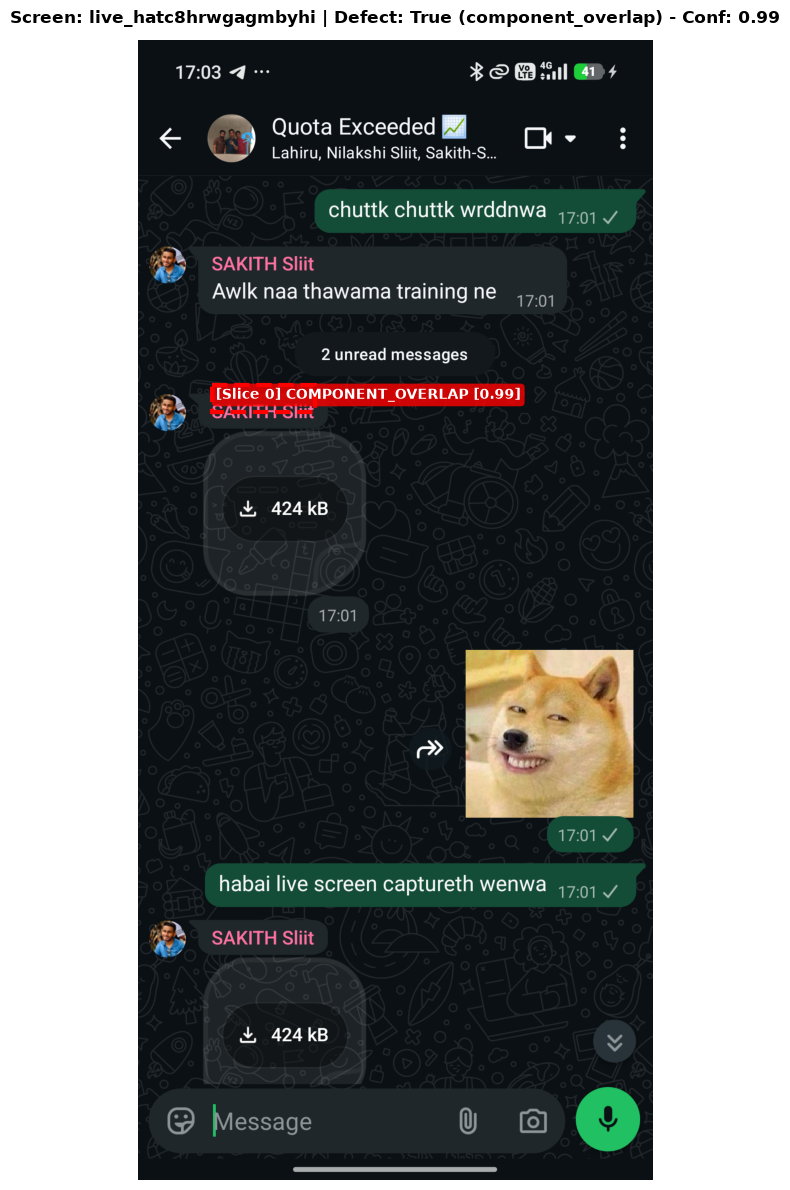


=== STRUCTURED IF-C3-to-C4 VERDICT ===
{
  "screen_id": "live_hatc8hrwgagmbyhi",
  "verdict": {
    "has_defect": true,
    "defect_type": "component_overlap",
    "sub_category": null,
    "confidence": 0.99,
    "bounding_box": [
      303,
      144,
      326,
      344
    ],
    "affected_element_id": "com.whatsapp:id/name_in_group_tv",
    "explanation": "Layout collision defect: Element 'com.whatsapp:id/name_in_group' occludes 'com.whatsapp:id/name_in_group_tv'."
  },
  "latency_breakdown": {
    "capture_ms": 6321.13,
    "preprocess_ms": 0.0,
    "prune_ms": 10.35,
    "inference_ms": 0.0,
    "total_pipeline_ms": 6331.48,
    "meets_sla": false
  },
  "timestamp": "2026-10-16T11:33:23.810605+00:00",
  "engine_used": "qwen2-vl-awq-4bit",
  "metadata": {
    "screen_id": "live_hatc8hrwgagmbyhi",
    "action_context": "Live device screen inspection",
    "pruning_stats": {
      "raw_nodes": 113,
      "pruned_nodes": 45,
      "reduction_pct": 60.18
    },
    "detected_by": 

In [30]:
# Cell 7: Live Device Screen & Hierarchy Capture (Interactive Device Picker)
from common.adb import AdbDevice, NoDeviceError

devices = AdbDevice.list_devices()
print(f'[*] Attached Devices Detected ({len(devices)}): {devices}')

if not devices:
    raise NoDeviceError('No Android device or emulator detected. Connect phone via USB or start emulator.')

# Select device: Set TARGET_SERIAL to specific device serial or index 0 for default
# Available options: 'hatc8hrwgagmbyhi' (Physical Phone), 'emulator-5554' (Emulator)
TARGET_SERIAL = None  # None selects first available if only 1; otherwise specify device serial

# If multiple devices detected and TARGET_SERIAL not set, default to first device (e.g. phone) with clear log
selected_serial = TARGET_SERIAL if TARGET_SERIAL else devices[0]
print(f'[+] Selecting Device: {selected_serial}')

device = AdbDevice(serial=selected_serial)
metrics = device.get_display_metrics()
print(f'[+] Device Connected : {device.serial}')
print(f'[+] Display Metrics  : {metrics["width"]}x{metrics["height"]} ({metrics["density"]} DPI) | Tall Screen: {metrics["is_tall"]}')

# Live evaluation with universal dynamic SAHI slicing
print('[*] Capturing live screen + hierarchy and running Vision Oracle...')
live_result = oracle.evaluate_device(
    device=device,
    enable_sahi=True,
    action_context='Live device screen inspection',
)

# Save captured live screen locally for visual review
live_screen_path = str(NOTEBOOK_DIR / f'live_captured_{device.serial}.png')
device.screencap(as_pil=True).save(live_screen_path)
print(f'[+] Saved live screenshot to: {live_screen_path}')

# Render visual bounding box overlay and print C4 JSON verdict
plot_oracle_result(live_screen_path, live_result)
